# Estimation of tree height using GEDI dataset - Data explore

## Jupyterlab setup, libraries installing and data retrieving  **[Ubuntu 26.04]**

## Getting the dataset

You can procede to install python libraries, using the apt install always in the terminal:

    sudo apt install python3-numpy python3-pandas python3-sklearn python3-matplotlib python3-rasterio python3-geopandas python3-seaborn python3-skimage python3-xarray

Being everything already installed, you can procede to to data archive download.

    
    cd ~/SE_data
    git pull
    rsync -hvrPt --ignore-existing ~/SE_data/* /media/sf_LVM_shared/my_SE_data
    cd  /media/sf_LVM_shared/my_SE_data/exercise
    pip install gdown
    ~/.local/bin/gdown 1Y60EuLsfmTICTX-U_FxcE1odNAf04bd-
    tar -xvzf tree_height.tar.gz
    
    # Start jupyter lab insede the python venv evenviroment
    jupyter-lab Tree_Height_01DataExplore.ipynb

## GEDI features

The Global Ecosystem Dynamics Investigation (GEDI) mission aims to characterize ecosystem structure and dynamics to enable radically improved quantification of biomass. The GEDI instrument, attached to the International Space Station (ISS), collects data globally between 51.6° N and 51.6° S latitudes at the highest resolution and densest sampling of the 3-dimensional structure of the Earth.

GEDI's Level 2A Geolocated Elevation and Height Metrics Product (GEDI02_A) is primarily composed of Relative Height (RH) metrics of canopy height stored at different percentiles.

The GEDI02_A product is provided in HDF5 format and has a spatial resolution (average footprint) of 25 meters. The GEDI02_A data product contains 156 layers for each of the eight beams, including ground elevation, canopy top height, relative return energy metrics (e.g., canopy vertical structure), and many other interpreted products from the return waveforms. 


The [GEDI_Subsetter.py](https://git.earthdata.nasa.gov/projects/LPDUR/repos/gedi-subsetter/browse) allows the conversion of the HDF5 format in to txt files. 
During the conversion several parameters can be extracted. The full list can be found at https://lpdaac.usgs.gov/documents/982/gedi_l2a_dictionary_P003_v2.html , and a general description is stored at https://lpdaac.usgs.gov/documents/986/GEDI02_UserGuide_V2.pdf

In [1]:
from IPython.display import Image
import rasterio
from rasterio import *
from rasterio.plot import show
from rasterio.plot import show_hist
import geopandas
import pandas as pd
from matplotlib import pyplot
#import skgstat as skg
import numpy as np
import seaborn as sns

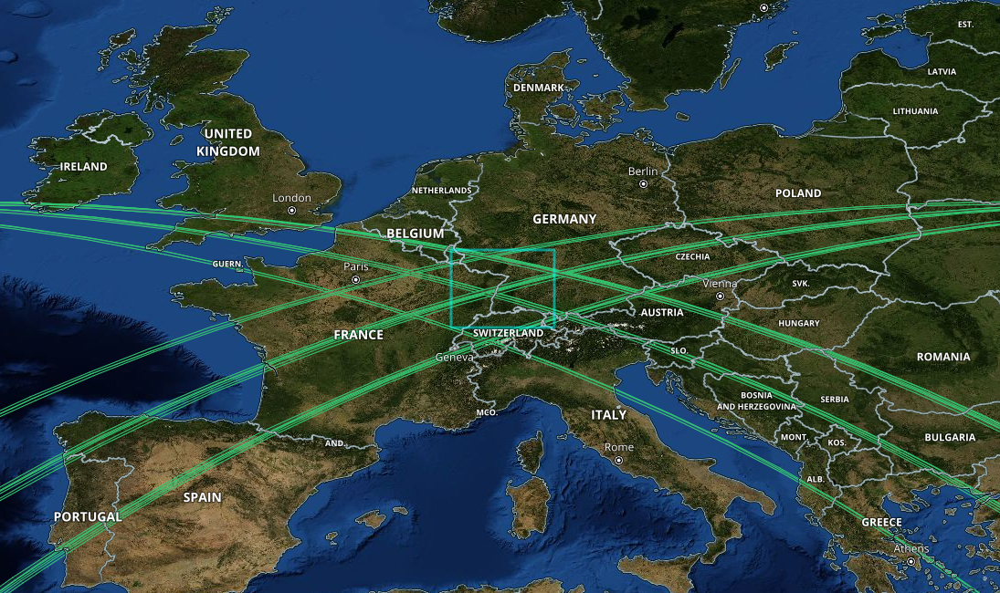

In [2]:
Image("../images/tree_height_path_map.png" , width = 500, height = 300)

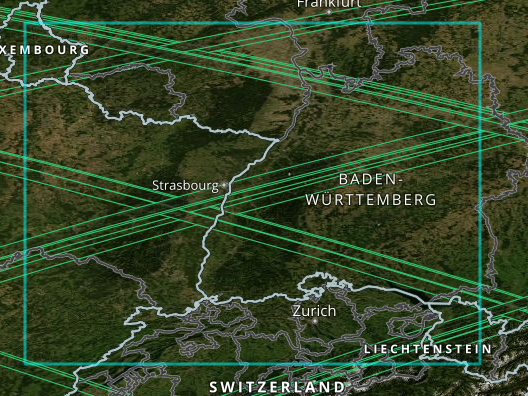

In [3]:
Image("../images/tree_height_study_area.png")

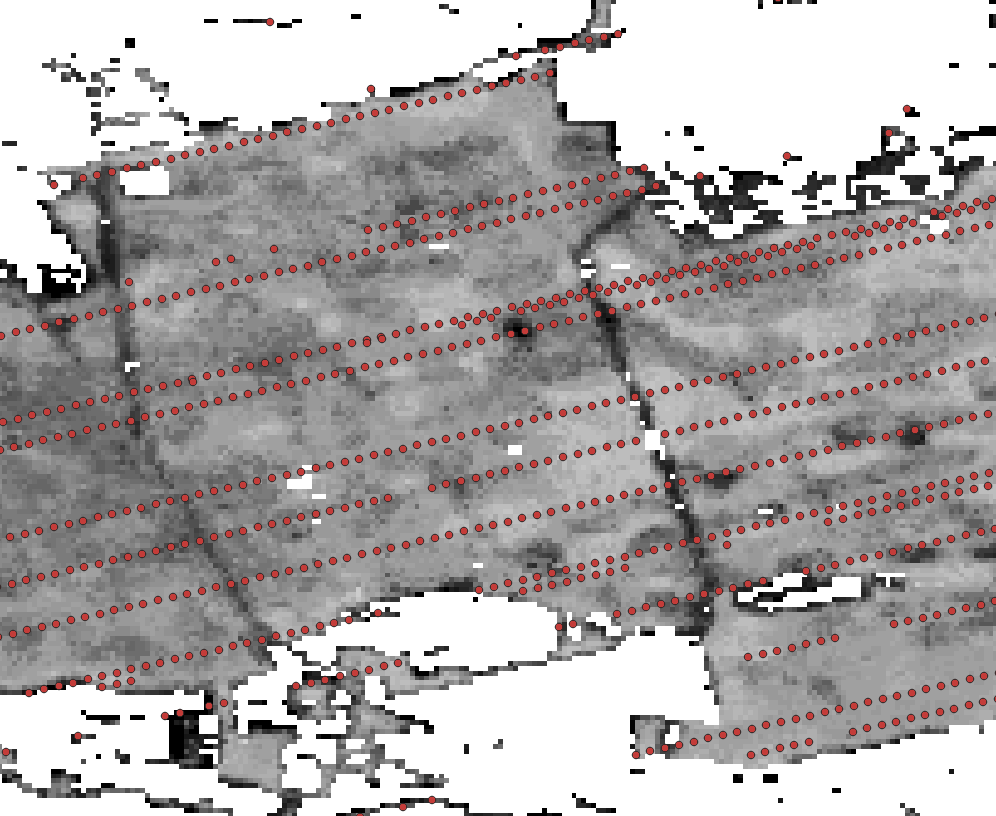

In [4]:
Image("../images/tree_height_study_area_selected.png" , width = 500, height = 300)

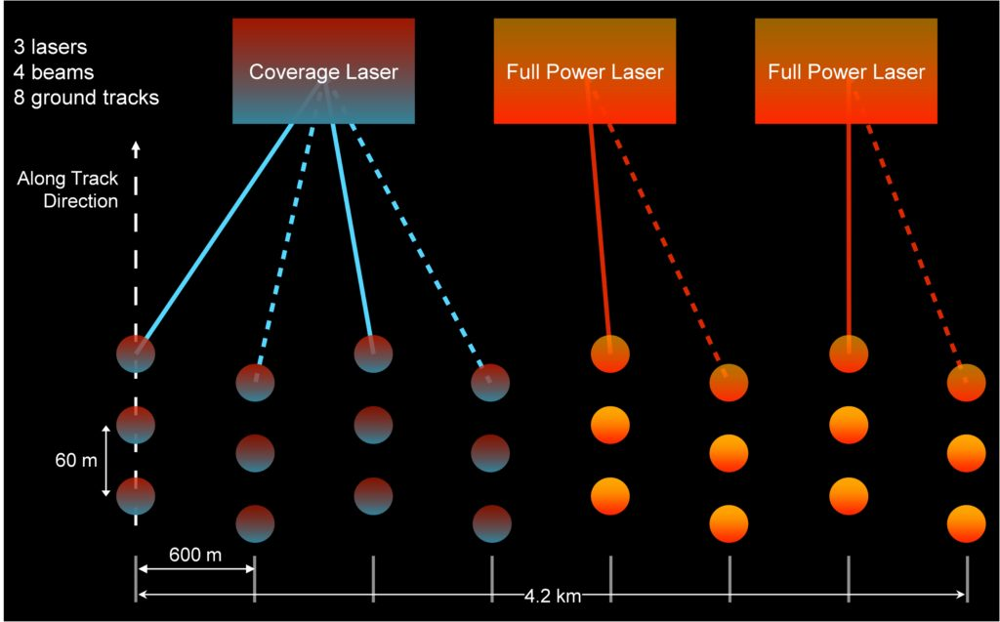

In [5]:
Image("../images/tree_height_beam.jpg" , width = 500, height = 300)

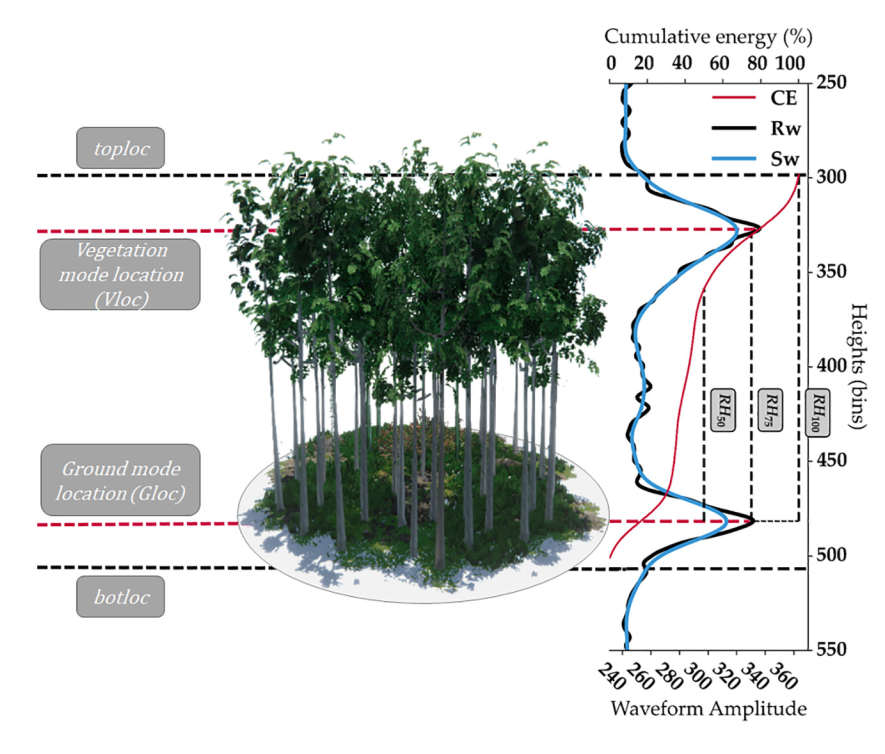

In [6]:
Image("../images/tree_height_pulse_distribution.png", width = 600, height = 300)

## Data presentation

### Available txt files

In [2]:
! ls tree_height/txt/*

tree_height/txt/eu_x_y_height_predictors_select.txt
tree_height/txt/eu_x_y_height_select.txt
tree_height/txt/eu_x_y_predictors_select.txt
tree_height/txt/eu_x_y_select.txt
tree_height/txt/eu_y_x_select_6algorithms_fullTable.txt


In [3]:
! wc -l tree_height/txt/*

  1267240 tree_height/txt/eu_x_y_height_predictors_select.txt
  1267240 tree_height/txt/eu_x_y_height_select.txt
  1267240 tree_height/txt/eu_x_y_predictors_select.txt
  1267239 tree_height/txt/eu_x_y_select.txt
  1267240 tree_height/txt/eu_y_x_select_6algorithms_fullTable.txt
  6336199 total


**File storing point location (longitude and latitude).**  
Such file can be used with "gdallocationinfo" to extract enviromental predictor at each point. 
The points have been already clean by removing all the points that falls in agricolture area, urban/built-up area, and water. In the immage below those areas are labeled in white.

In [9]:
! head tree_height/txt/eu_x_y_select.txt

6.050001 49.727499
6.0500017 49.922155
6.0500021 48.602377
6.0500089 48.151979
6.0500102 49.58841
6.0500143 48.608456
6.0500165 48.571401
6.0500189 49.921613
6.0500201 48.822645
6.0500238 49.847522


<AxesSubplot:>

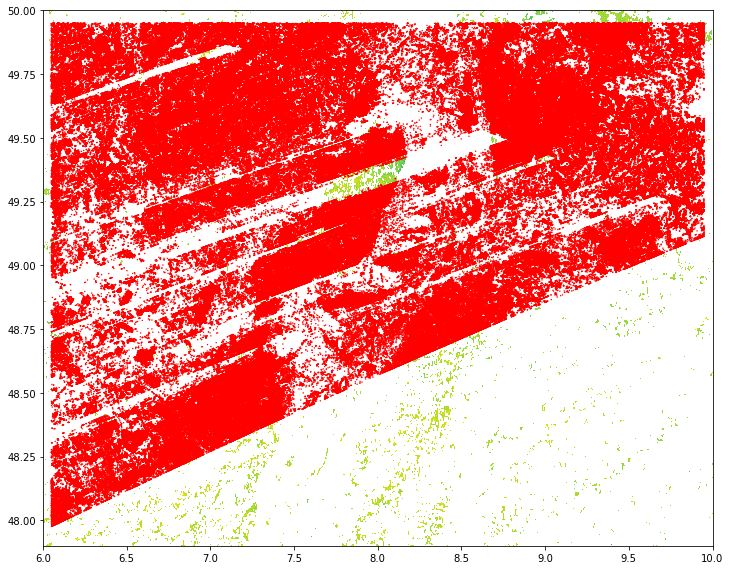

In [29]:
points = geopandas.read_file("tree_height/geodata_vector/eu_x_y_height_select.gpkg")
raster = rasterio.open("tree_height/geodata_raster/treecover.tif")
fig, ax = pyplot.subplots(figsize=(12, 12))
rasterio.plot.show(raster, ax=ax)
points.plot(ax=ax, facecolor='red', edgecolor='none', markersize=2)

**File storing tree hight (cm) obtained by 6 algorithms, with their associate quality flags.**
The quality flags can be used to refine and select the best tree height estimation and use it as tree height observation.

* a?_95: tree hight (cm) at 95 quintile, for each algorithm  
* min_rh_95: minimum value of tree hight (cm) ammong the 6 algorithms  
* max_rh_95: maximum value of tree hight (cm) ammong the 6 algorithms  
* BEAM: 1-4 coverage beam = lower power (worse) ; 5-8 power beam = higher power (better)  
* digital_elev: digital mdoel elevation  
* elev_low: elevation of center of lowest mode  
* qc_a?: quality_flag for six algorithms quality_flag = 1 (better); = 0 (worse)  
* se_a?: sensitivity for six algorithms sensitivity < 0.95 (worse);  sensitivity > 0.95  (better )  
* deg_fg: (degrade_flag) not-degraded 0 (better) ;  degraded > 0 (worse)  
* solar_ele: solar elevation. > 0 day (worse); < 0 night (better)  

In [30]:
height_6algorithms = pd.read_csv("tree_height/txt/eu_y_x_select_6algorithms_fullTable.txt", sep=" ",  index_col=False)
pd.set_option('display.max_columns',None)
height_6algorithms.head(6)

,ID,X,Y,a1_95,a2_95,a3_95,a4_95,a5_95,a6_95,min_rh_95,max_rh_95,BEAM,digital_elev,elev_low,qc_a1,qc_a2,qc_a3,qc_a4,qc_a5,qc_a6,se_a1,se_a2,se_a3,se_a4,se_a5,se_a6,deg_fg,solar_ele
0,1,6.050001,49.727499,3139,3139,3139,3120,3139,3139,3120,3139,5,410.0,383.72153,1,1,1,1,1,1,0.962,0.984,0.968,0.962,0.989,0.979,0,17.7
1,2,6.050002,49.922155,1022,2303,970,872,5596,1524,872,5596,5,290.0,2374.14110,0,0,0,0,0,0,0.948,0.990,0.960,0.948,0.994,0.980,0,43.7
2,3,6.050002,48.602377,380,1336,332,362,1336,1340,332,1340,4,440.0,435.97781,1,1,1,1,1,1,0.947,0.975,0.956,0.947,0.981,0.968,0,0.2
3,4,6.050009,48.151979,3153,3142,3142,3127,3138,3142,3127,3153,2,450.0,422.00537,1,1,1,1,1,1,0.930,0.970,0.943,0.930,0.978,0.962,0,-14.2
4,5,6.050010,49.588410,666,4221,651,33,5611,2723,33,5611,8,370.0,2413.74830,0,0,0,0,0,0,0.941,0.983,0.946,0.941,0.992,0.969,0,22.1
5,6,6.050014,48.608456,787,1179,1187,761,1833,1833,761,1833,3,420.0,415.51581,1,1,1,1,1,1,0.952,0.979,0.961,0.952,0.986,0.975,0,0.2


In [31]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
height_6algorithms.describe()

,ID,X,Y,a1_95,a2_95,a3_95,a4_95,a5_95,a6_95,min_rh_95,max_rh_95,BEAM,digital_elev,elev_low,qc_a1,qc_a2,qc_a3,qc_a4,qc_a5,qc_a6,se_a1,se_a2,se_a3,se_a4,se_a5,se_a6,deg_fg,solar_ele
count,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00,1267239.00
mean,633620.00,7.97,49.37,1807.40,2164.35,1885.92,1587.37,2692.24,2129.05,1582.89,2703.53,4.75,289.22,491.06,0.80,0.91,0.85,0.80,0.92,0.90,0.93,0.97,0.95,0.93,0.98,0.96,12.46,-1.33
std,365820.53,1.10,0.47,1034.72,1107.12,1013.52,1058.24,1310.33,1045.41,1056.13,1322.65,2.29,10363.92,528.74,0.40,0.28,0.35,0.40,0.26,0.30,0.44,0.19,0.36,0.44,0.14,0.25,25.89,30.75
min,1.00,6.05,47.98,115.00,82.00,37.00,3.00,78.00,82.00,3.00,116.00,1.00,-1000000.00,114.87,0.00,0.00,0.00,0.00,0.00,0.00,-411.76,-178.46,-339.98,-411.76,-124.62,-232.30,0.00,-63.60
25%,316810.50,7.03,49.06,882.00,1474.00,1095.00,488.00,1921.00,1457.00,486.00,1928.00,3.00,320.00,309.49,1.00,1.00,1.00,1.00,1.00,1.00,0.92,0.97,0.94,0.92,0.98,0.96,0.00,-23.40
50%,633620.00,7.84,49.51,1899.00,2240.00,1960.00,1650.00,2706.00,2230.00,1644.00,2711.00,5.00,390.00,386.05,1.00,1.00,1.00,1.00,1.00,1.00,0.95,0.98,0.96,0.95,0.99,0.97,0.00,-4.90
75%,950429.50,8.98,49.73,2590.00,2817.00,2626.00,2472.00,3414.00,2812.00,2468.00,3416.00,7.00,470.00,476.89,1.00,1.00,1.00,1.00,1.00,1.00,0.97,0.99,0.97,0.97,0.99,0.98,0.00,23.30
max,1267239.00,9.95,49.95,14359.00,16070.00,14469.00,13620.00,18000.00,18299.00,13620.00,18299.00,8.00,1200.00,8566.18,1.00,1.00,1.00,1.00,1.00,1.00,181.09,84.12,153.38,181.09,63.34,111.83,80.00,64.00


Count observation during the day (>0) and during the night (<0)

In [32]:
(height_6algorithms["solar_ele"] < 0).sum()   # night (better)

700460

In [33]:
(height_6algorithms["solar_ele"] > 0).sum()   # day (worse)

566779

Count uniq degraged (>0) or not-degraded (0) observation

In [34]:
height_6algorithms["deg_fg"].value_counts()

0     967716
70    139223
30     48378
5      44063
80     42052
50     16666
9       5815
71      1406
1       1368
35       481
39        71
Name: deg_fg, dtype: int64

In [35]:
height_6algorithms["solar_ele"].value_counts()

-35.10    17572
-35.20    11174
-20.60    10390
-16.80     9658
25.60      7223
          ...  
10.00         2
-0.40         1
-60.40        1
42.10         1
-32.40        1
Name: solar_ele, Length: 1101, dtype: int64

**File storing point location and tree height. The height is obtained as average of the 4 algorithms.**
Among the 6 algorithms we calculate minimum and maximum of heith values, then we calculate the mean excluding the minimum and the maximum. 

In [36]:
! head tree_height/txt/eu_x_y_height_select.txt

ID X Y h
1 6.050001 49.727499 3139
2 6.0500017 49.922155 1454.75
3 6.0500021 48.602377 853.5
4 6.0500089 48.151979 3141
5 6.0500102 49.58841 2065.25
6 6.0500143 48.608456 1246.5
7 6.0500165 48.571401 2938.75
8 6.0500189 49.921613 3294.75
9 6.0500201 48.822645 1623.5
/bin/bash: -c: line 1: syntax error near unexpected token `newline'
/bin/bash: -c: line 1: ` paste -d " "  tree_height/txt/eu_x_y_height_select.txt >'


### Available geo raster files

In [37]:
! ls tree_height/geodata_raster

BLDFIE_WeigAver.tif    glad_ard_SVVI_med.tif
CECSOL_WeigAver.tif    glad_ard_SVVI_min.tif
CHELSA_bio18.tif       latitude.tif
CHELSA_bio4.tif        longitude.tif
convergence.tif        northness.tif
cti.tif		       ORCDRC_WeigAver.tif
dev-magnitude.tif      outlet_dist_dw_basin.tif
eastness.tif	       SBIO3_Isothermality_5_15cm.tif
elev.tif	       SBIO4_Temperature_Seasonality_5_15cm.tif
forestheight.tif       treecover.tif
glad_ard_SVVI_max.tif


The geo raster have been standarized in terms of extent and pixel resolution, using *gdal_translate* and *gdal_edit.py*

In [38]:
! gdalinfo tree_height/geodata_raster/glad_ard_SVVI_min.tif

Driver: GTiff/GeoTIFF
Files: tree_height/geodata_raster/glad_ard_SVVI_min.tif
Size is 16000, 8400
Coordinate System is:
GEOGCRS["WGS 84",
    ENSEMBLE["World Geodetic System 1984 ensemble",
        MEMBER["World Geodetic System 1984 (Transit)"],
        MEMBER["World Geodetic System 1984 (G730)"],
        MEMBER["World Geodetic System 1984 (G873)"],
        MEMBER["World Geodetic System 1984 (G1150)"],
        MEMBER["World Geodetic System 1984 (G1674)"],
        MEMBER["World Geodetic System 1984 (G1762)"],
        MEMBER["World Geodetic System 1984 (G2139)"],
        ELLIPSOID["WGS 84",6378137,298.257223563,
            LENGTHUNIT["metre",1]],
        ENSEMBLEACCURACY[2.0]],
    PRIMEM["Greenwich",0,
        ANGLEUNIT["degree",0.0174532925199433]],
    CS[ellipsoidal,2],
        AXIS["geodetic latitude (Lat)",north,
            ORDER[1],
            ANGLEUNIT["degree",0.0174532925199433]],
        AXIS["geodetic longitude (Lon)",east,
            ORDER[2],
            ANGLEUNIT["degr

The urban building, agricolture land and water has been maskout using *pksetmask* and set as No-datga. In the following maps it is rappresented in white color. Point location has been moved accordingly. 

### Geo raster files description.

**Spectral Variability Vegetation Index obtained from the [GLAD ARD](https://glad.umd.edu/ard/glad-landsat-ard-tools) dataset.** 

* glad_ard_SVVI_min.tif: Spectral Variability Vegetation Index colculated using a 3 years temporal minimum composite. 
* glad_ard_SVVI_med.tif: Spectral Variability Vegetation Index colculated using a 3 years temporal median composite.
* glad_ard_SVVI_max.tif: Spectral Variability Vegetation Index colculated using a 3 years temporal maximum composite.

<Axes: title={'center': 'glad_ard_SVVI_max.tif'}>

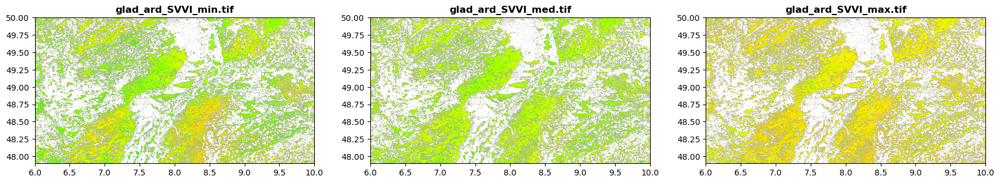

In [2]:
src1 = rasterio.open("tree_height/geodata_raster/glad_ard_SVVI_min.tif")
src2 = rasterio.open("tree_height/geodata_raster/glad_ard_SVVI_med.tif")
src3 = rasterio.open("tree_height/geodata_raster/glad_ard_SVVI_max.tif")
fig, (src1p,src2p,src3p) = pyplot.subplots(1,3, figsize=(21,7))
show(src1, ax=src1p, title='glad_ard_SVVI_min.tif' , cmap='gist_rainbow' )
show(src2, ax=src2p, title='glad_ard_SVVI_med.tif' , cmap='gist_rainbow' )
show(src3, ax=src3p, title='glad_ard_SVVI_max.tif' , cmap='gist_rainbow' )

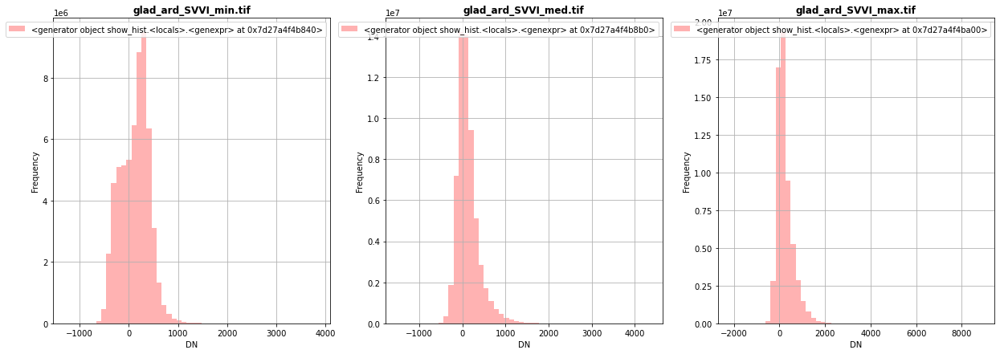

In [11]:
fig, (src1p,src2p,src3p) = pyplot.subplots(1,3, figsize=(21,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="glad_ard_SVVI_min.tif")
show_hist( src2, ax=src2p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="glad_ard_SVVI_med.tif")
show_hist( src3, ax=src3p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="glad_ard_SVVI_max.tif")

**Climate data obained from the [CHELSA](https://chelsa-climate.org/bioclim/) dataset.** 

* CHELSA_bio18.tif: mean monthly precipitation amount of the warmest quarter
* CHELSA_bio4.tif: temperature seasonality (standard deviation of the monthly mean temperatures)

<Axes: title={'center': 'CHELSA_bio18'}>

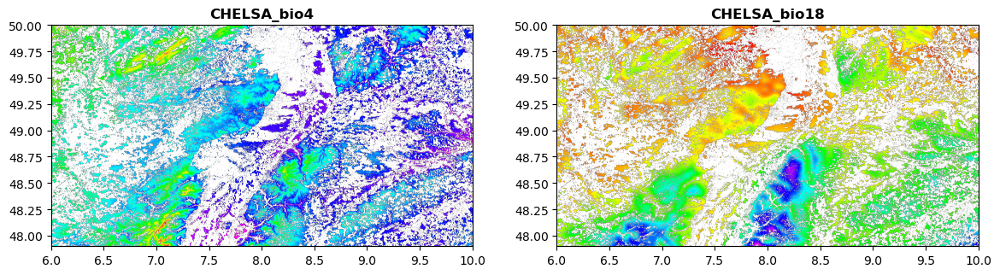

In [6]:
import rasterio
from rasterio.plot import show
src1 = rasterio.open("tree_height/geodata_raster/CHELSA_bio4.tif")
src2 = rasterio.open("tree_height/geodata_raster/CHELSA_bio18.tif")
fig, (src1p,src2p) = pyplot.subplots(1,2, figsize=(14,7))
show((src1), ax=src1p, title='CHELSA_bio4'  , cmap='gist_rainbow')
show((src2), ax=src2p, title='CHELSA_bio18' , cmap='gist_rainbow')

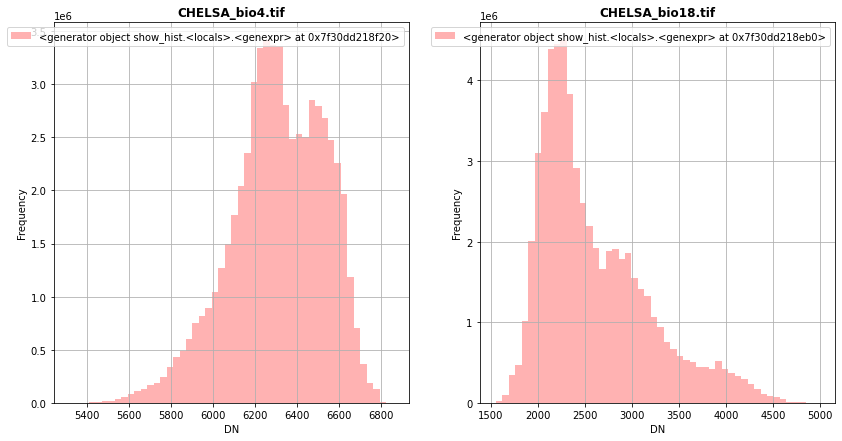

In [25]:
fig, (src1p,src2p) = pyplot.subplots(1,2, figsize=(14,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="CHELSA_bio4.tif")
show_hist( src2, ax=src2p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="CHELSA_bio18.tif")

**Soil data obained from the [SOILGRID](https://soilgrids.org/)**

* BLDFIE_WeigAver.tif: Bulk density (fine earth) in kg / cubic-meter (weigheted average as function for the depth)
* CECSOL_WeigAver.tif: Cation exchange capacity of soil in cmolc/kg (weigheted average as function for the depth)
* ORCDRC_WeigAver.tif: Soil organic carbon content (fine earth fraction) in g per kg (weigheted average as function for the depth)

<Axes: title={'center': 'ORCDRC_WeigAver.tif'}>

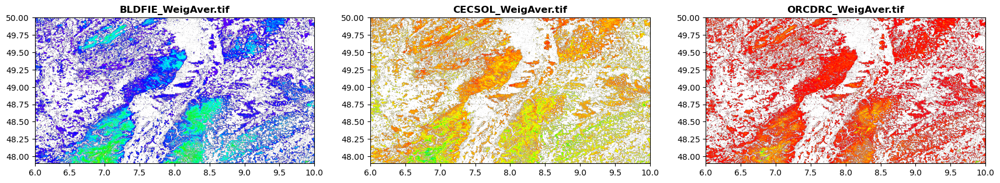

In [3]:
src1 = rasterio.open("tree_height/geodata_raster/BLDFIE_WeigAver.tif")
src2 = rasterio.open("tree_height/geodata_raster/CECSOL_WeigAver.tif")
src3 = rasterio.open("tree_height/geodata_raster/ORCDRC_WeigAver.tif")
fig, (src1p,src2p,src3p) = pyplot.subplots(1,3, figsize=(21,7))
show(src1, ax=src1p, title='BLDFIE_WeigAver.tif' , cmap='gist_rainbow')
show(src2, ax=src2p, title='CECSOL_WeigAver.tif' , cmap='gist_rainbow')
show(src3, ax=src3p, title='ORCDRC_WeigAver.tif' , cmap='gist_rainbow')

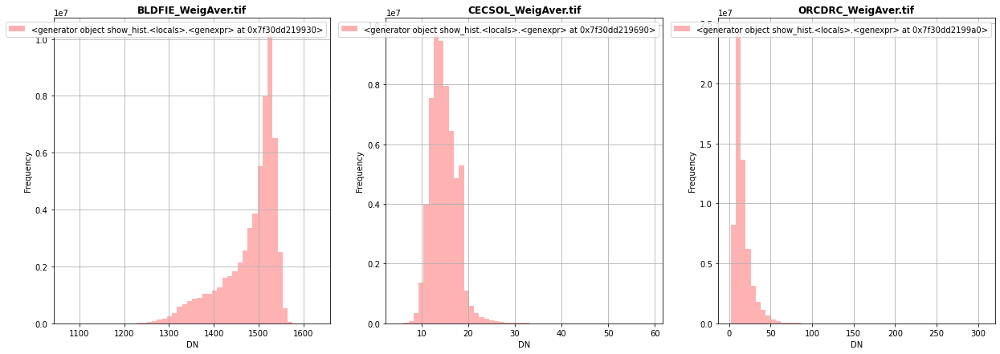

In [27]:
fig, (src1p,src2p,src3p) = pyplot.subplots(1,3, figsize=(21,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="BLDFIE_WeigAver.tif")
show_hist( src2, ax=src2p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="CECSOL_WeigAver.tif")
show_hist( src3, ax=src3p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="ORCDRC_WeigAver.tif")

**Geomorphological data obtained from [geomorpho90m](http://spatial-ecology.net/docs/build/html/GEODATA/geomorpho90m/geomorpho90m.html)**

* elev.tif: elevation
* convergence.tif: convergence 
* northness.tif: northness
* eastness.tif: eastness
* dev-magnitude.tif: Maximum multiscaledeviation

<Axes: title={'center': 'dev-magnitude.tif'}>

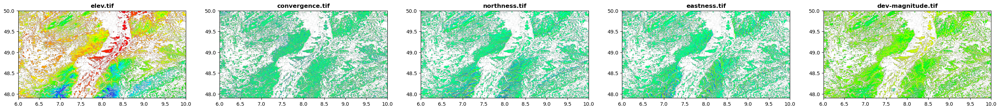

In [2]:
src1 = rasterio.open("tree_height/geodata_raster/elev.tif")
src2 = rasterio.open("tree_height/geodata_raster/convergence.tif")
src3 = rasterio.open("tree_height/geodata_raster/northness.tif")
src4 = rasterio.open("tree_height/geodata_raster/eastness.tif")
src5 = rasterio.open("tree_height/geodata_raster/dev-magnitude.tif")
fig, (src1p,src2p,src3p,src4p,src5p) = pyplot.subplots(1,5, figsize=(35,7))
show(src1, ax=src1p, title='elev.tif' ,  cmap='gist_rainbow')
show(src2, ax=src2p, title='convergence.tif' , cmap='gist_rainbow')
show(src3, ax=src3p, title='northness.tif' , cmap='gist_rainbow')
show(src4, ax=src4p, title='eastness.tif', cmap='gist_rainbow')
show(src5, ax=src5p, title='dev-magnitude.tif' , cmap='gist_rainbow')

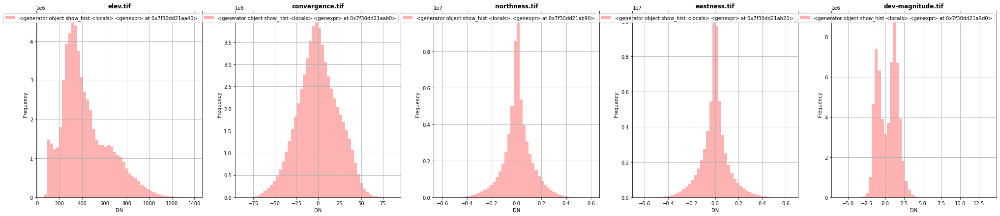

In [29]:
fig, (src1p,src2p,src3p,src4p,src5p) = pyplot.subplots(1,5, figsize=(35,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="elev.tif")
show_hist( src2, ax=src2p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="convergence.tif")
show_hist( src3, ax=src3p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="northness.tif")
show_hist( src4, ax=src4p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="eastness.tif")
show_hist( src5, ax=src5p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="dev-magnitude.tif")

**Hydrography data obtained from [hydromorpho90m](https://essd.copernicus.org/preprints/essd-2022-9/)**

* cti.tif:Compound topographic index
* outlet_dist_dw_basin.tif: Distance between focal grid cell and the outlet grid cell in the network 

<Axes: title={'center': 'outlet_dist_dw_basin.tif'}>

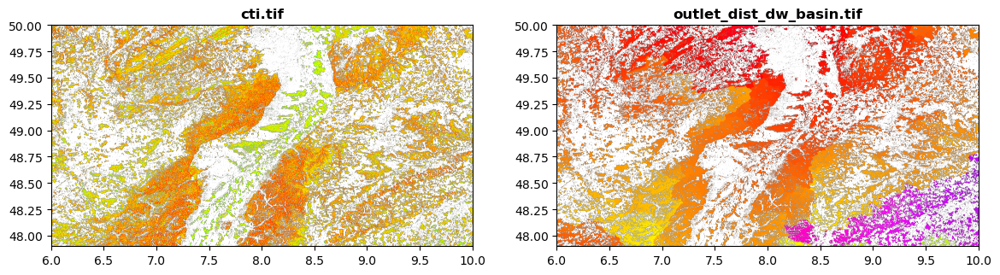

In [4]:
src1 = rasterio.open("tree_height/geodata_raster/cti.tif")
src2 = rasterio.open("tree_height/geodata_raster/outlet_dist_dw_basin.tif")
fig, (src1p,src2p) = pyplot.subplots(1,2, figsize=(14,7))
show((src1), ax=src1p, title='cti.tif' , cmap='gist_rainbow')
show((src2), ax=src2p, title='outlet_dist_dw_basin.tif' , cmap='gist_rainbow')

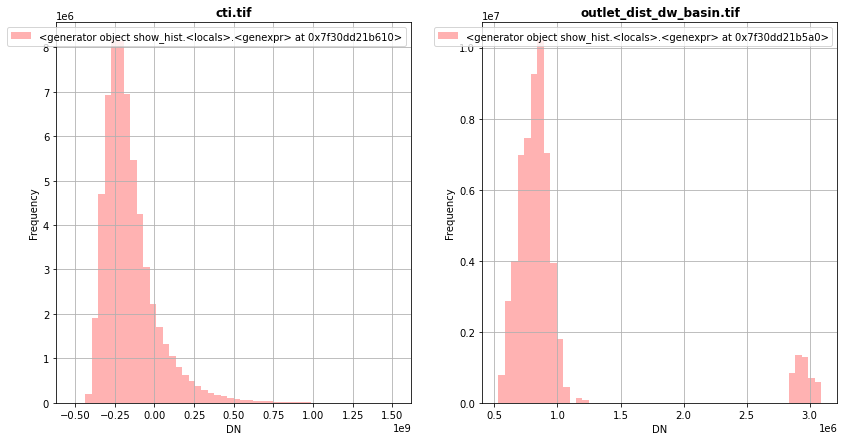

In [31]:
fig, (src1p,src2p) = pyplot.subplots(1,2, figsize=(14,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="cti.tif")
show_hist( src2, ax=src2p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="outlet_dist_dw_basin.tif")

**Soil data obtained from [Global Soil Bioclimatic variables](https://zenodo.org/record/4558732#.YmqPg3VfiV4)**

* SBIO3_Isothermality_5_15cm.tif
* SBIO4_Temperature_Seasonality_5_15cm.tif

<Axes: title={'center': 'SBIO4_Temperature_Seasonality_5_15cm.tif'}>

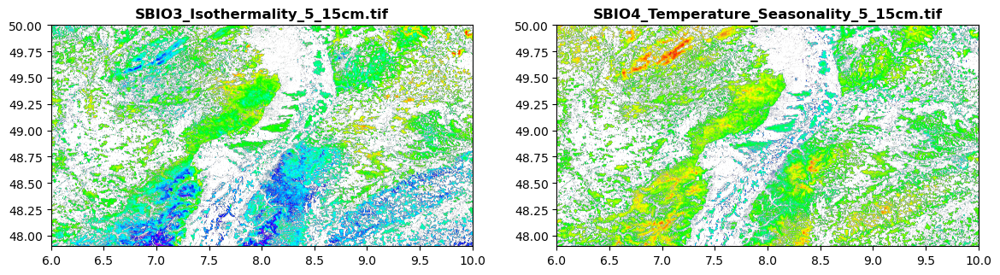

In [15]:
src1 = rasterio.open("tree_height/geodata_raster/SBIO3_Isothermality_5_15cm.tif")
src2 = rasterio.open("tree_height/geodata_raster/SBIO4_Temperature_Seasonality_5_15cm.tif")
fig, (src1p,src2p) = pyplot.subplots(1,2, figsize=(14,7))
show((src1), ax=src1p, title='SBIO3_Isothermality_5_15cm.tif', cmap='gist_rainbow')
show((src2), ax=src2p, title='SBIO4_Temperature_Seasonality_5_15cm.tif', cmap='gist_rainbow')

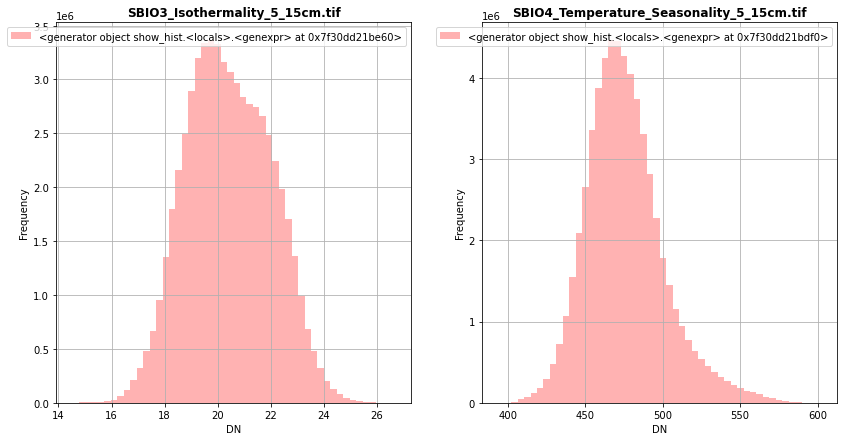

In [33]:
fig, (src1p,src2p) = pyplot.subplots(1,2, figsize=(14,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="SBIO3_Isothermality_5_15cm.tif")
show_hist( src2, ax=src2p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="SBIO4_Temperature_Seasonality_5_15cm.tif")

**Forest cover in percentage obtained from [Global Forest Change](https://earthenginepartners.appspot.com/science-2013-global-forest/download_v1.7.html)**

* treecover.tif: canopy cover in percentage

<Axes: title={'center': 'treecover.tif'}>

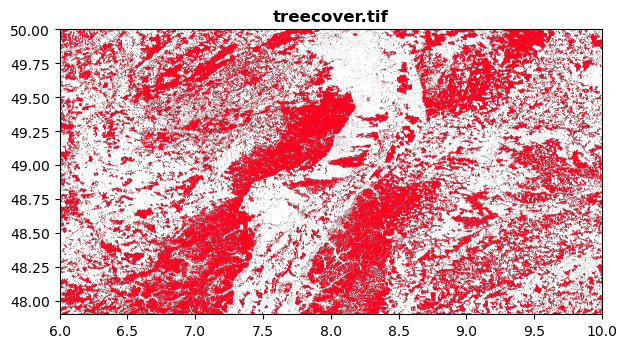

In [29]:
src1 = rasterio.open("tree_height/geodata_raster/treecover.tif")
fig, src1p = pyplot.subplots(1,1, figsize=(7,7))
show(src1, ax=src1p, title='treecover.tif', vmin=0 , vmax=100 , cmap='gist_rainbow')

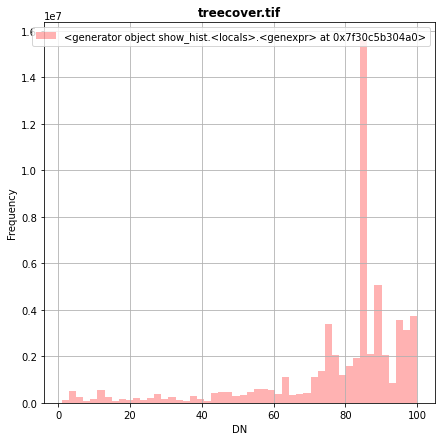

In [35]:
fig, (src1p) = pyplot.subplots(1,1, figsize=(7,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="treecover.tif")

**Forest height in percentage obtained from [Forest Height](https://glad.umd.edu/dataset/gedi)**


The [Global Forest Canopy Height, 2019](https://glad.umd.edu/dataset/gedi) map has been release in 2020 (scientific publication https://doi.org/10.1016/j.rse.2020.112165). The authors use a regression tree model that was calibrated and applied to each individual Landsat GLAD ARD tile (1 × 1◦) in a “moving window” mode. Such tree height estimation is storede in forestheight.tiff and in the table as *forestheight* column.
We will try to beats such estimation using a more advance ML tecnques and different enviromental predictors that better express the ecolocacal condition.


* forestheight.tif

<Axes: title={'center': 'forestheight.tiff'}>

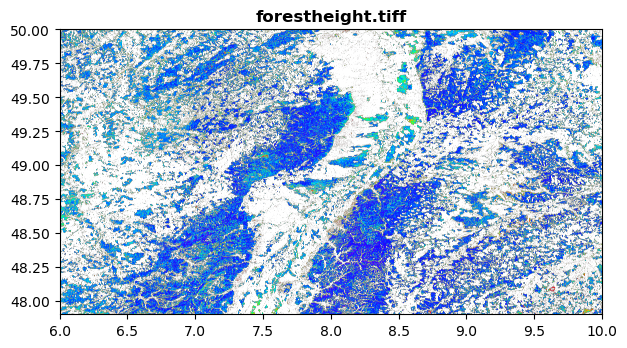

In [2]:
src1 = rasterio.open("tree_height/geodata_raster/forestheight.tif")
fig, src1p = pyplot.subplots(1,1, figsize=(7,7))
show(src1, ax=src1p, title='forestheight.tiff' , cmap='gist_rainbow')

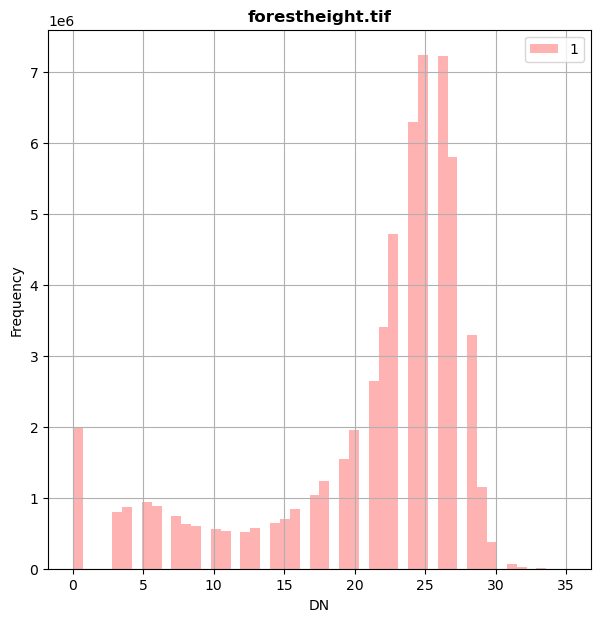

In [3]:
fig, src1p = pyplot.subplots(1,1, figsize=(7,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="forestheight.tif"  )

**Latitude and longittude obtained from GRASS (r.latlong)[https://grass.osgeo.org/grass78/manuals/r.latlong.html]**

* longitude.tif
* latitude.tif   

<Axes: title={'center': 'latitude.tif'}>

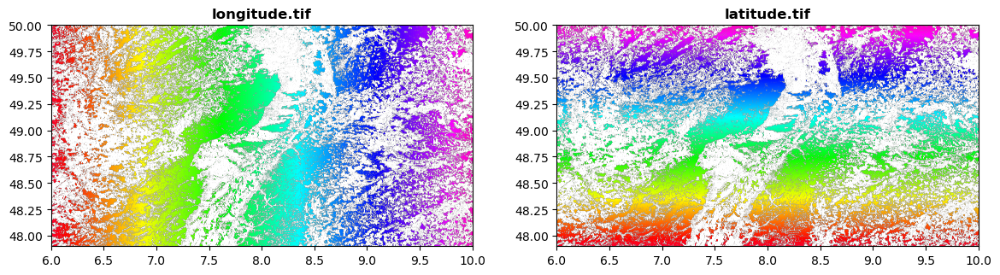

In [4]:
src1 = rasterio.open("tree_height/geodata_raster/longitude.tif")
src2 = rasterio.open("tree_height/geodata_raster/latitude.tif")
fig, (src1p, src2p) = pyplot.subplots(1,2, figsize=(14,7))
show(src1, ax=src1p, title='longitude.tif' , cmap='gist_rainbow')
show(src2, ax=src2p, title='latitude.tif' , cmap='gist_rainbow')

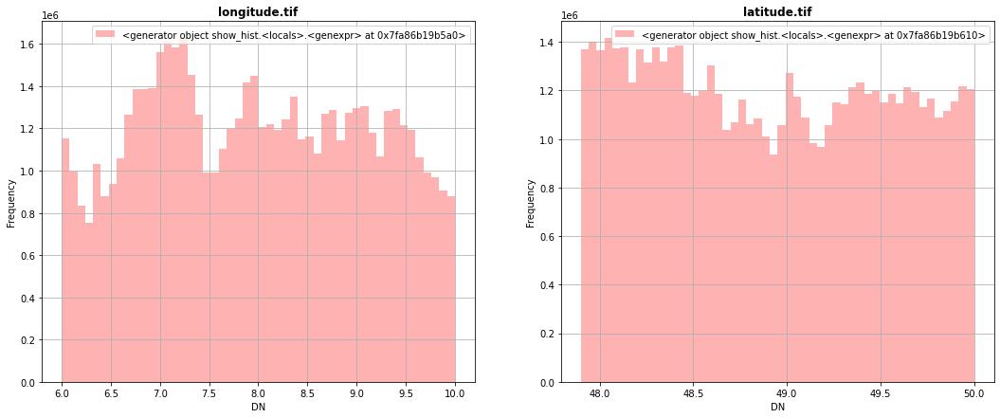

In [6]:
fig, (src1p,src2p) = pyplot.subplots(1,2, figsize=(18,7))
show_hist( src1, ax=src1p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="longitude.tif")
show_hist( src2, ax=src2p, bins=50, lw=0.0, stacked=False, alpha=0.3, histtype='stepfilled', title="latitude.tif")

**File storing enviromental predictors at each point location.**

In [7]:
predictors = pd.read_csv("tree_height/txt/eu_x_y_height_predictors_select.txt", sep=" ",  index_col=False)
pd.set_option('display.max_columns',None)
predictors.head(6)

,ID,X,Y,h,BLDFIE_WeigAver,CECSOL_WeigAver,CHELSA_bio18,CHELSA_bio4,convergence,cti,dev-magnitude,eastness,elev,forestheight,glad_ard_SVVI_max,glad_ard_SVVI_med,glad_ard_SVVI_min,northness,ORCDRC_WeigAver,outlet_dist_dw_basin,SBIO3_Isothermality_5_15cm,SBIO4_Temperature_Seasonality_5_15cm,treecover
0,1,6.050001,49.727499,3139.00,1540,13,2113,5893,-10.486560,-238043120,1.158417,0.069094,353.983124,23,276.871094,46.444092,347.665405,0.042500,9,780403,19.798992,440.672211,85
1,2,6.050002,49.922155,1454.75,1491,12,1993,5912,33.274361,-208915344,-1.755341,0.269112,267.511688,19,-49.526367,19.552734,-130.541748,0.182780,16,772777,20.889412,457.756195,85
2,3,6.050002,48.602377,853.50,1521,17,2124,5983,0.045293,-137479792,1.908780,-0.016055,389.751160,21,93.257324,50.743652,384.522461,0.036253,14,898820,20.695877,481.879700,62
3,4,6.050009,48.151979,3141.00,1526,16,2569,6130,-33.654274,-267223072,0.965787,0.067767,380.207703,27,542.401367,202.264160,386.156738,0.005139,15,831824,19.375000,479.410278,85
4,5,6.050010,49.588410,2065.25,1547,14,2108,5923,27.493824,-107809368,-0.162624,0.014065,308.042786,25,136.048340,146.835205,198.127441,0.028847,17,796962,18.777500,457.880066,85
5,6,6.050014,48.608456,1246.50,1515,19,2124,6010,-1.602039,17384282,1.447979,-0.018912,364.527100,18,221.339844,247.387207,480.387939,0.042747,14,897945,19.398880,474.331329,62


In [8]:
pd.set_option('display.float_format', lambda x: '%.5f' % x)
predictors.describe()

,ID,X,Y,h,BLDFIE_WeigAver,CECSOL_WeigAver,CHELSA_bio18,CHELSA_bio4,convergence,cti,dev-magnitude,eastness,elev,forestheight,glad_ard_SVVI_max,glad_ard_SVVI_med,glad_ard_SVVI_min,northness,ORCDRC_WeigAver,outlet_dist_dw_basin,SBIO3_Isothermality_5_15cm,SBIO4_Temperature_Seasonality_5_15cm,treecover
count,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000,1267239.00000
mean,633620.00000,7.96654,49.36511,1994.97683,1502.39574,13.68642,2310.15649,6293.88506,-0.14166,-149126079.37575,0.25312,-0.00370,338.88664,20.75837,250.98824,119.72647,148.13463,0.00737,13.97081,749213.04208,19.79155,476.60503,77.64616
std,365820.53323,1.10181,0.46899,977.86026,44.27063,2.21764,366.82038,224.88881,23.15530,166804129.24955,1.31914,0.10254,130.18989,7.31751,349.75421,257.31665,267.01116,0.10150,7.08598,100361.51781,1.31156,27.05428,21.02552
min,1.00000,6.05000,47.97635,84.75000,1216.00000,6.00000,1553.00000,5503.00000,-81.28032,-474056768.00000,-5.47250,-0.63450,82.19376,0.00000,-865.58301,-699.90332,-842.19458,-0.52740,3.00000,540427.00000,14.61014,394.21213,1.00000
25%,316810.50000,7.02639,49.05567,1326.75000,1491.00000,12.00000,2078.00000,6149.00000,-15.25398,-259747944.00000,-0.99220,-0.05173,259.10744,19.00000,16.96252,-43.99414,-37.99170,-0.04133,9.00000,674957.00000,18.90800,458.58015,75.00000
50%,633620.00000,7.84351,49.51040,2078.00000,1518.00000,13.00000,2242.00000,6304.00000,-0.66545,-188826192.00000,0.46544,-0.00116,331.79755,24.00000,162.78882,70.64990,182.67358,0.00359,12.00000,742105.00000,19.76031,473.55383,85.00000
75%,950429.50000,8.97501,49.73179,2676.00000,1531.00000,15.00000,2457.00000,6477.00000,15.50443,-84776040.00000,1.31942,0.04273,408.29001,26.00000,405.89746,220.47534,324.65247,0.05970,16.00000,811864.00000,20.62271,491.08063,89.00000
max,1267239.00000,9.95000,49.95000,14481.00000,1599.00000,38.00000,4618.00000,6814.00000,79.13613,1393578752.00000,11.05419,0.56048,1097.69751,34.00000,4506.54102,4149.77930,3570.01855,0.55303,139.00000,1028934.00000,26.08103,598.17474,100.00000


### Assessing variable autocorrelation

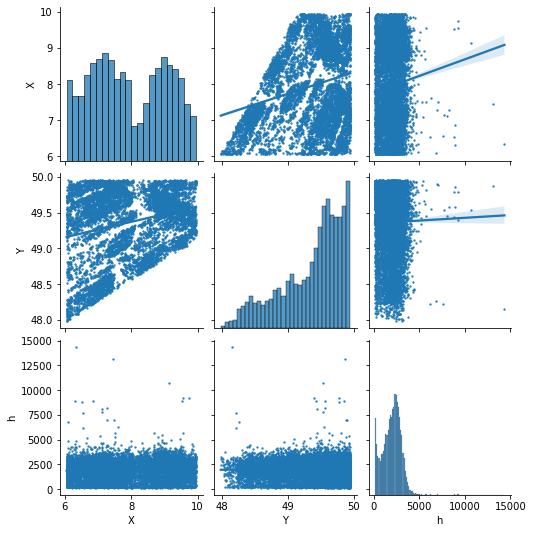

In [9]:
predictors_sample = predictors[["X","Y","h"]].sample(10000)
sns.pairplot(predictors_sample ,  kind="reg", plot_kws=dict(scatter_kws=dict(s=2)))  
pyplot.show()

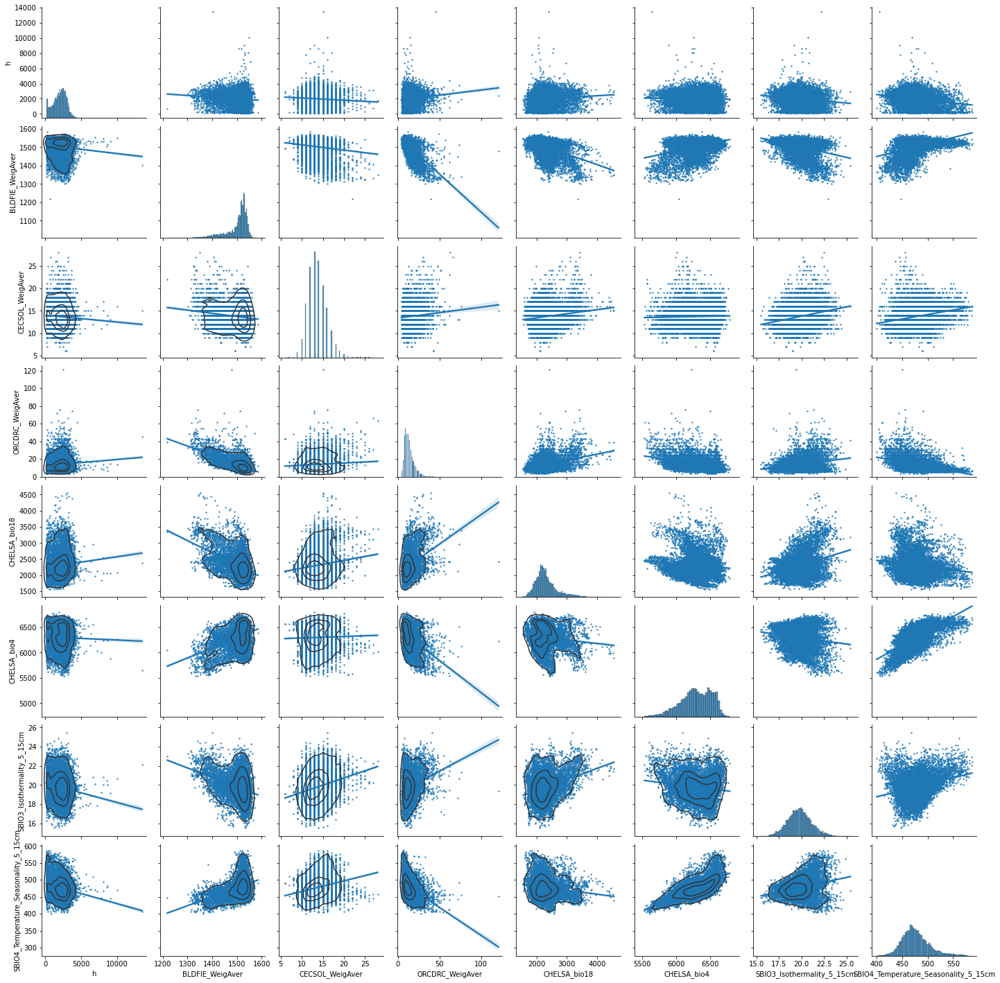

In [10]:
predictors_sample = predictors[["h","BLDFIE_WeigAver","CECSOL_WeigAver","ORCDRC_WeigAver","CHELSA_bio18","CHELSA_bio4","SBIO3_Isothermality_5_15cm","SBIO4_Temperature_Seasonality_5_15cm"]].sample(10000)
g = sns.pairplot(predictors_sample , kind="reg", plot_kws=dict(scatter_kws=dict(s=2)) )  
g.map_lower(sns.kdeplot, levels=4, color=".2")

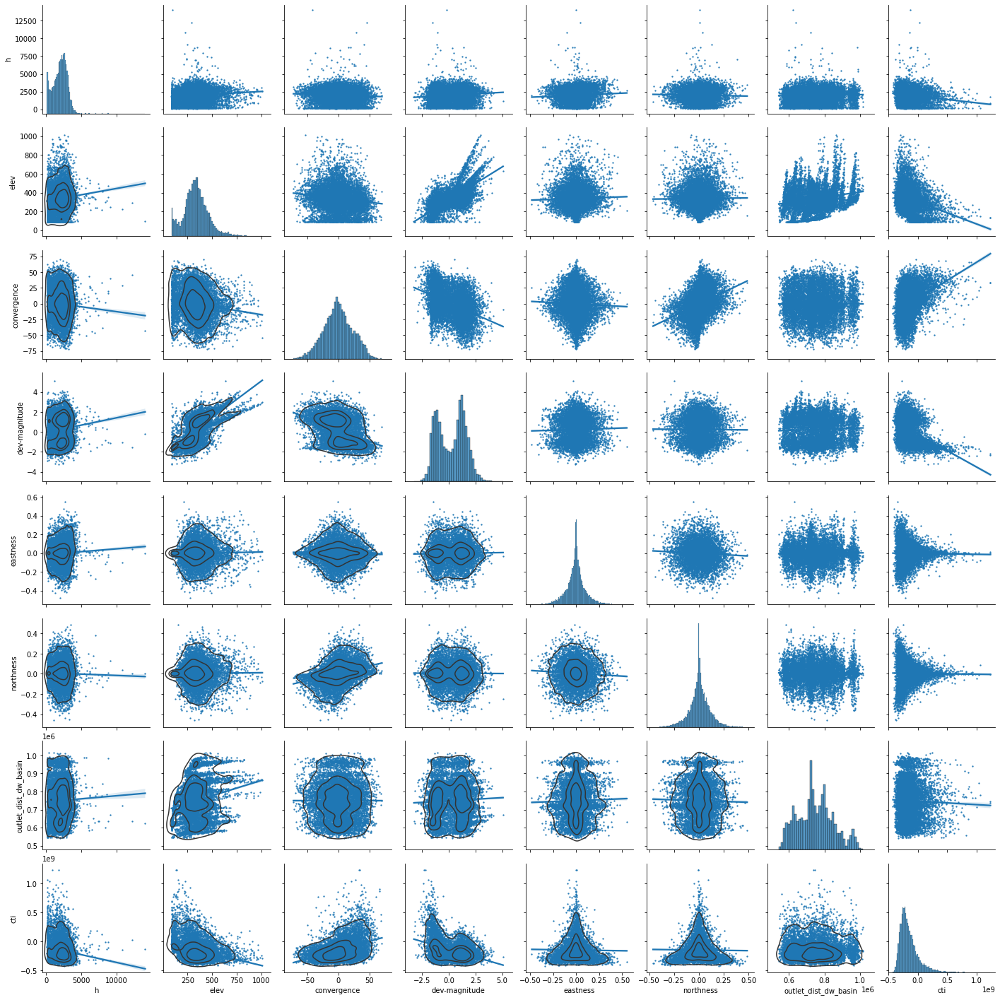

In [11]:
predictors_sample = predictors[["h","elev","convergence","dev-magnitude","eastness","northness","outlet_dist_dw_basin","cti"]].sample(10000)
g = sns.pairplot(predictors_sample , kind="reg", plot_kws=dict(scatter_kws=dict(s=2)) )  
g.map_lower(sns.kdeplot, levels=4, color=".2")

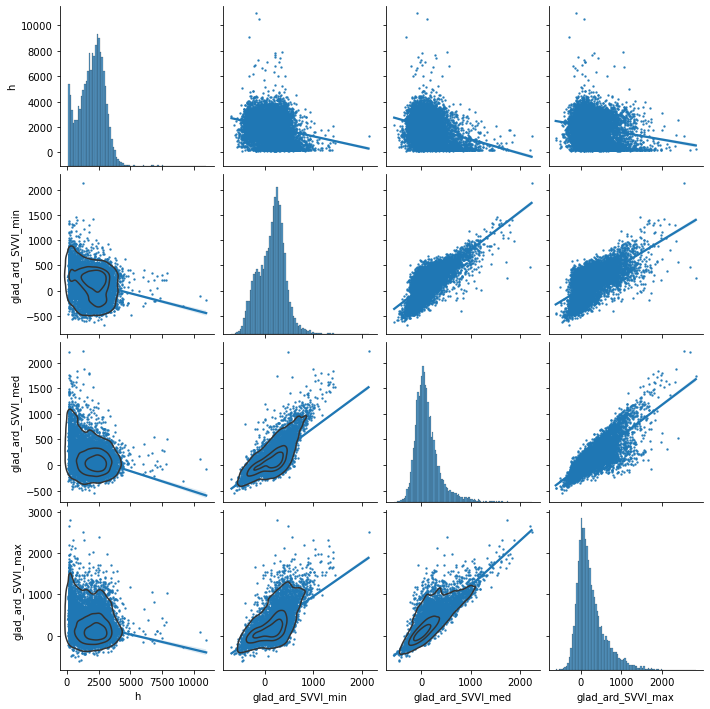

In [12]:
predictors_sample = predictors[["h","glad_ard_SVVI_min","glad_ard_SVVI_med","glad_ard_SVVI_max" ]].sample(10000)
g = sns.pairplot(predictors_sample , kind="reg", plot_kws=dict(scatter_kws=dict(s=2)) )  
g.map_lower(sns.kdeplot, levels=4, color=".2")

In [13]:
### Assessing spatial autocorrelation

In [14]:
xy_val = pd.read_csv("tree_height/txt/eu_x_y_height_select.txt", sep=" ")
xy_val_sample = xy_val.sample(10000)
xy_val_sample.head()

,ID,X,Y,h
1156667,1156668,9.49292,49.93394,1117.75000
1024856,1024857,9.14997,49.39489,1876.50000
708611,708612,8.16510,48.92672,219.50000
1008972,1008973,9.11153,49.49667,2431.75000
113330,113331,6.45285,48.26761,2423.50000


/home/user/.local/lib/python3.10/site-packages/skgstat/plotting/variogram_plot.py:123: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


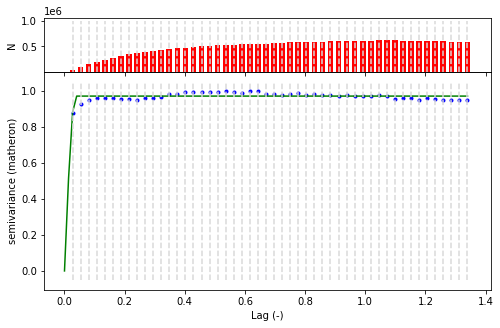

In [15]:
V = skg.Variogram(list(zip(xy_val_sample.X,xy_val_sample.Y)) , xy_val_sample.h ,  maxlag = 'median' ,  n_lags=50 )
fig = V.plot()